# Uso de Suelo

In [1]:
import geopandas as gpd

mexico_dirty = gpd.read_file("/home/dusty/Documents/Repositories/proyecto_agronomia/data/pure/INEGI/889463842781_s/conjunto_de_datos/cdv_usuev250sVII_cnal.shp")

In [2]:
import re

dirty_types = mexico_dirty['DESCRIPCIO'].unique().tolist()
q = [d for d in dirty_types if re.search("AGRI", d)]

agro = mexico_dirty[mexico_dirty['DESCRIPCIO'].isin(q)]

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

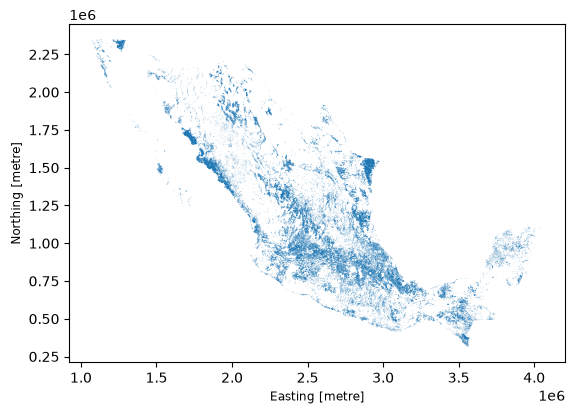

In [3]:
agro.plot()

In [4]:
agro.shape[0]

35667

In [5]:
mexico = gpd.read_file("/home/dusty/Documents/Repositories/proyecto_agronomia/preload/Mexico/conjunto_de_datos/00mun.shp")

In [7]:
mexico

,CVEGEO,CVE_ENT,CVE_MUN,NOMGEO,geometry
0,01001,01,001,Aguascalientes,"POLYGON ((2488980.227 1117358.447, 2489013.495..."
1,01008,01,008,San José de Gracia,"POLYGON ((2453326.553 1143576.423, 2453363.325..."
2,01011,01,011,San Francisco de los Romo,"POLYGON ((2483638.349 1120034.022, 2483946.175..."
3,01009,01,009,Tepezalá,"POLYGON ((2481826.447 1149055.253, 2481589.222..."
4,01007,01,007,Rincón de Romos,"POLYGON ((2476760.231 1150329.046, 2476783.634..."
...,...,...,...,...,...
2473,32004,32,004,Benito Juárez,"POLYGON ((2336381.078 1064884.55, 2336405.02 1..."
2474,32043,32,043,Susticacán,"POLYGON ((2380699.092 1186256.441, 2380731.393..."
2475,32042,32,042,Sombrerete,"POLYGON ((2323463.845 1340295.088, 2323485.623..."
2476,32014,32,014,General Francisco R. Murguía,"POLYGON ((2395056.891 1381032.418, 2395060.211..."


In [34]:
v = gpd.sjoin(mexico, agro, how="left", predicate="contains")

/tmp/ipykernel_81380/2265883616.py:1: UserWarning: CRS mismatch between the CRS of left geometries and the CRS of right geometries.
Use `to_crs()` to reproject one of the input geometries to match the CRS of the other.

Left CRS: EPSG:6372
Right CRS: PROJCS["Albers_Conic_Equal_Area",GEOGCS["GCS_GRS_1 ...

  v = gpd.sjoin(mexico, agro, how="left", predicate="contains")


In [36]:
v

,CVEGEO,CVE_ENT,CVE_MUN,NOMGEO,geometry,index_right,CLAVE,DESCRIPCIO
0,01001,01,001,Aguascalientes,"POLYGON ((2488980.227 1117358.447, 2489013.495...",89952.0,RAS,AGRICULTURA DE RIEGO ANUAL Y SEMIPERMANENTE
0,01001,01,001,Aguascalientes,"POLYGON ((2488980.227 1117358.447, 2489013.495...",108091.0,TA,AGRICULTURA DE TEMPORAL ANUAL
0,01001,01,001,Aguascalientes,"POLYGON ((2488980.227 1117358.447, 2489013.495...",108110.0,TA,AGRICULTURA DE TEMPORAL ANUAL
0,01001,01,001,Aguascalientes,"POLYGON ((2488980.227 1117358.447, 2489013.495...",86256.0,RA,AGRICULTURA DE RIEGO ANUAL
0,01001,01,001,Aguascalientes,"POLYGON ((2488980.227 1117358.447, 2489013.495...",108131.0,TA,AGRICULTURA DE TEMPORAL ANUAL
...,...,...,...,...,...,...,...,...
2476,32014,32,014,General Francisco R. Murguía,"POLYGON ((2395056.891 1381032.418, 2395060.211...",111614.0,TA,AGRICULTURA DE TEMPORAL ANUAL
2476,32014,32,014,General Francisco R. Murguía,"POLYGON ((2395056.891 1381032.418, 2395060.211...",111718.0,TA,AGRICULTURA DE TEMPORAL ANUAL
2476,32014,32,014,General Francisco R. Murguía,"POLYGON ((2395056.891 1381032.418, 2395060.211...",111742.0,TA,AGRICULTURA DE TEMPORAL ANUAL
2477,32009,32,009,Chalchihuites,"POLYGON ((2309544.252 1287852.255, 2310471.535...",110652.0,TA,AGRICULTURA DE TEMPORAL ANUAL


In [37]:
vson = v[v['CVE_ENT']=="26"]

In [40]:
vson

,CVEGEO,CVE_ENT,CVE_MUN,NOMGEO,geometry,index_right,CLAVE,DESCRIPCIO
1910,26037,26,037,Mazatán,"POLYGON ((1697891.507 1912357.193, 1697808.161...",117832.0,TA,AGRICULTURA DE TEMPORAL ANUAL
1911,26036,26,036,Magdalena,"POLYGON ((1622879.079 2139463.927, 1623149.689...",88318.0,RA,AGRICULTURA DE RIEGO ANUAL
1911,26036,26,036,Magdalena,"POLYGON ((1622879.079 2139463.927, 1623149.689...",88329.0,RA,AGRICULTURA DE RIEGO ANUAL
1911,26036,26,036,Magdalena,"POLYGON ((1622879.079 2139463.927, 1623149.689...",88330.0,RA,AGRICULTURA DE RIEGO ANUAL
1911,26036,26,036,Magdalena,"POLYGON ((1622879.079 2139463.927, 1623149.689...",88363.0,RA,AGRICULTURA DE RIEGO ANUAL
...,...,...,...,...,...,...,...,...
1981,26002,26,002,Agua Prieta,"POLYGON ((1760930.103 2160351.208, 1767001.04 ...",88478.0,RA,AGRICULTURA DE RIEGO ANUAL
1981,26002,26,002,Agua Prieta,"POLYGON ((1760930.103 2160351.208, 1767001.04 ...",90546.0,RAS,AGRICULTURA DE RIEGO ANUAL Y SEMIPERMANENTE
1981,26002,26,002,Agua Prieta,"POLYGON ((1760930.103 2160351.208, 1767001.04 ...",88515.0,RA,AGRICULTURA DE RIEGO ANUAL
1981,26002,26,002,Agua Prieta,"POLYGON ((1760930.103 2160351.208, 1767001.04 ...",90549.0,RAS,AGRICULTURA DE RIEGO ANUAL Y SEMIPERMANENTE
